In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime, timedelta

import random
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

print("Source path:", SRC_PATH)
print("Source path exists:", SRC_PATH.exists())

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Libraries imported successfully!")

Source path: /Users/furkaninc/Desktop/synthetic_fraud_project/src
Source path exists: True
Libraries imported successfully!


In [2]:
# Dataset configuration

N_TRANSACTIONS = 100_000
N_ACCOUNTS = 10_000

FRAUD_RATE = 0.015
N_FRAUD_TRANSACTIONS = int(
    N_TRANSACTIONS * FRAUD_RATE
)

N_NORMAL_TRANSACTIONS = (
    N_TRANSACTIONS - N_FRAUD_TRANSACTIONS
)

SIMULATION_DAYS = 30

START_DATE = datetime(2026, 1, 1)

RANDOM_STATE = 42

print("Total transactions:", N_TRANSACTIONS)
print("Total accounts:", N_ACCOUNTS)
print("Normal transactions:", N_NORMAL_TRANSACTIONS)
print("Fraud transactions:", N_FRAUD_TRANSACTIONS)
print("Fraud rate:", FRAUD_RATE * 100, "%")
print("Simulation days:", SIMULATION_DAYS)

Total transactions: 100000
Total accounts: 10000
Normal transactions: 98500
Fraud transactions: 1500
Fraud rate: 1.5 %
Simulation days: 30


In [3]:
import sys

sys.path.append(str(Path.cwd().parent / "src"))

from customer_generator import generate_customers

customers = generate_customers(
    n_accounts=N_ACCOUNTS,
    random_state=RANDOM_STATE
)

print("Customer dataset shape:", customers.shape)

display(customers.head())

Customer dataset shape: (10000, 7)


,account_id,customer_id,account_type,initial_balance,risk_profile,home_location,registered_device
0,ACC_000001,CUST_000001,PREMIUM,4882.13,LOW,Ankara,DEV_000001
1,ACC_000002,CUST_000002,STANDARD,15221.71,LOW,Ankara,DEV_000002
2,ACC_000003,CUST_000003,PREMIUM,56736.89,LOW,Izmir,DEV_000003
3,ACC_000004,CUST_000004,STANDARD,3058.36,LOW,Adana,DEV_000004
4,ACC_000005,CUST_000005,STANDARD,8277.33,MEDIUM,Konya,DEV_000005


In [4]:
print("Account type distribution:")
display(
    customers["account_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nRisk profile distribution:")
display(
    customers["risk_profile"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nBalance statistics:")
display(customers["initial_balance"].describe().round(2))

Account type distribution:


account_type
STANDARD    70.58
PREMIUM     19.57
BUSINESS     9.85
Name: proportion, dtype: float64


Risk profile distribution:


risk_profile
LOW       64.37
MEDIUM    30.67
HIGH       4.96
Name: proportion, dtype: float64


Balance statistics:


count      10000.00
mean       22593.10
std        66357.32
min          100.71
25%         3436.20
50%         7792.39
75%        19872.47
max      3802774.15
Name: initial_balance, dtype: float64

In [5]:
from transaction_generator import generate_normal_transactions

normal_transactions = generate_normal_transactions(
    customers=customers,
    n_transactions=N_NORMAL_TRANSACTIONS,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=RANDOM_STATE
)

print("Normal transactions shape:", normal_transactions.shape)

display(normal_transactions.head())

Normal transactions shape: (98476, 11)


,transaction_id,timestamp,sender_id,receiver_id,transaction_type,amount,sender_balance_before,sender_balance_after,device_id,location,is_fraud
0,TXN_0000001,2026-01-01 00:00:34.132897690,ACC_005643,ACC_003307,CASH_OUT,226.47,41772.42,41545.95,DEV_005643,Gaziantep,0
1,TXN_0000002,2026-01-01 00:00:34.427735075,ACC_002326,ACC_002724,PAYMENT,381.23,88299.25,87918.02,DEV_002326,Antalya,0
2,TXN_0000003,2026-01-01 00:00:49.868826972,ACC_002387,ACC_005028,TRANSFER,36.73,213644.33,213607.60,DEV_002387,Bursa,0
3,TXN_0000004,2026-01-01 00:01:11.188848846,ACC_002952,ACC_009419,CASH_OUT,20.02,4911.69,4891.67,DEV_002952,Konya,0
4,TXN_0000005,2026-01-01 00:02:02.367877342,ACC_004445,ACC_007201,TRANSFER,49.03,8264.50,8215.47,DEV_004445,Istanbul,0


In [6]:
print("Transaction type distribution:")

display(
    normal_transactions["transaction_type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTransaction amount statistics:")

display(
    normal_transactions["amount"].describe().round(2)
)

print("\nTimestamp range:")

print(normal_transactions["timestamp"].min())
print(normal_transactions["timestamp"].max())

print("\nFraud count:")
print(normal_transactions["is_fraud"].sum())

Transaction type distribution:


transaction_type
PAYMENT     35.05
TRANSFER    30.09
CASH_OUT    20.02
CASH_IN     14.84
Name: proportion, dtype: float64


Transaction amount statistics:


count    98476.00
mean        92.20
std        160.31
min          0.24
25%         21.19
50%         45.15
75%         99.03
max       9457.13
Name: amount, dtype: float64


Timestamp range:
2026-01-01 00:00:34.132897690
2026-01-30 23:59:43.756698067

Fraud count:
0


In [7]:
print("Shape:", normal_transactions.shape)
print("Fraud count:", normal_transactions["is_fraud"].sum())
print("Unique senders:", normal_transactions["sender_id"].nunique())
print("Unique receivers:", normal_transactions["receiver_id"].nunique())
print("Missing values:", normal_transactions.isnull().sum().sum())

Shape: (98476, 11)
Fraud count: 0
Unique senders: 10000
Unique receivers: 9999
Missing values: 0


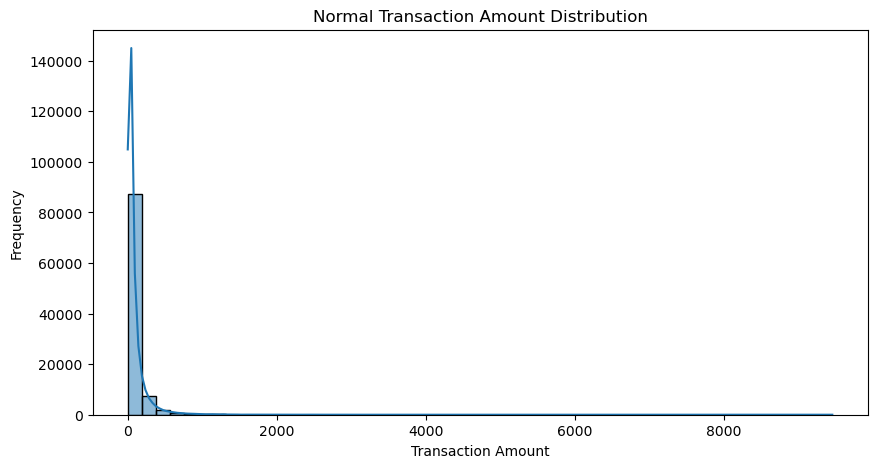

In [8]:
# Transaction amount distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=normal_transactions,
    x="amount",
    bins=50,
    kde=True
)

plt.title("Normal Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

In [9]:
# Transaction counts per sender

sender_activity = (
    normal_transactions
    .groupby("sender_id")
    .size()
)

display(sender_activity.describe().round(2))

count    10000.00
mean         9.85
std          3.14
min          1.00
25%          8.00
50%         10.00
75%         12.00
max         23.00
dtype: float64

In [10]:
sender_balances = customers.set_index(
    "account_id"
)["initial_balance"]

transaction_balance_check = normal_transactions.copy()

transaction_balance_check["sender_initial_balance"] = (
    transaction_balance_check["sender_id"]
    .map(sender_balances)
)

transaction_balance_check["insufficient_balance"] = (
    transaction_balance_check["amount"]
    > transaction_balance_check["sender_initial_balance"]
)

print(
    "Transactions exceeding initial sender balance:",
    transaction_balance_check["insufficient_balance"].sum()
)

print(
    "Percentage:",
    round(
        transaction_balance_check["insufficient_balance"].mean() * 100,
        2
    ),
    "%"
)

Transactions exceeding initial sender balance: 8
Percentage: 0.01 %


In [11]:
from pathlib import Path
import sys

print("Current directory:", Path.cwd())
print("Parent directory:", Path.cwd().parent)

PROJECT_ROOT = Path.cwd().parent
SRC_PATH = PROJECT_ROOT / "src"

print("SRC exists:", SRC_PATH.exists())
print("SRC path:", SRC_PATH.resolve())
print("Files in SRC:", list(SRC_PATH.glob("*")))

Current directory: /Users/furkaninc/Desktop/synthetic_fraud_project/notebooks
Parent directory: /Users/furkaninc/Desktop/synthetic_fraud_project
SRC exists: True
SRC path: /Users/furkaninc/Desktop/synthetic_fraud_project/src
Files in SRC: [PosixPath('/Users/furkaninc/Desktop/synthetic_fraud_project/src/customer_generator.py'), PosixPath('/Users/furkaninc/Desktop/synthetic_fraud_project/src/transaction_generator.py'), PosixPath('/Users/furkaninc/Desktop/synthetic_fraud_project/src/__pycache__')]


In [12]:
import sys
import importlib
from pathlib import Path

SRC_PATH = Path.cwd().parent / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import transaction_generator

importlib.reload(transaction_generator)

print("Module imported successfully!")

Module imported successfully!


In [13]:
import customer_generator
import importlib

importlib.reload(customer_generator)

customers = customer_generator.generate_customers(
    n_accounts=N_ACCOUNTS,
    random_state=RANDOM_STATE
)

print("Customers shape:", customers.shape)

Customers shape: (10000, 7)


In [14]:
normal_transactions = transaction_generator.generate_normal_transactions(
    customers=customers,
    n_transactions=N_NORMAL_TRANSACTIONS,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=RANDOM_STATE
)

print("Transactions shape:", normal_transactions.shape)
print(normal_transactions.columns.tolist())

Transactions shape: (98476, 11)
['transaction_id', 'timestamp', 'sender_id', 'receiver_id', 'transaction_type', 'amount', 'sender_balance_before', 'sender_balance_after', 'device_id', 'location', 'is_fraud']


In [15]:
# Check sender balance consistency

invalid_transactions = normal_transactions[
    normal_transactions["sender_balance_before"]
    < normal_transactions["amount"]
]

negative_balances = normal_transactions[
    normal_transactions["sender_balance_after"] < 0
]

print("Invalid transactions:", len(invalid_transactions))
print("Negative ending balances:", len(negative_balances))

print(
    "Minimum sender balance before:",
    normal_transactions["sender_balance_before"].min()
)

print(
    "Minimum sender balance after:",
    normal_transactions["sender_balance_after"].min()
)

Invalid transactions: 10
Negative ending balances: 0
Minimum sender balance before: 0.0
Minimum sender balance after: 0.0


In [16]:
print("Transaction types:")
display(normal_transactions["transaction_type"].value_counts())

print("\nDate range:")
print(normal_transactions["timestamp"].min())
print(normal_transactions["timestamp"].max())

print("\nUnique senders:", normal_transactions["sender_id"].nunique())
print("Unique receivers:", normal_transactions["receiver_id"].nunique())

Transaction types:


transaction_type
PAYMENT     34518
TRANSFER    29627
CASH_OUT    19713
CASH_IN     14618
Name: count, dtype: int64


Date range:
2026-01-01 00:00:34.132897690
2026-01-30 23:59:43.756698067

Unique senders: 10000
Unique receivers: 9999


In [17]:
outgoing_transactions = normal_transactions[
    normal_transactions["transaction_type"] != "CASH_IN"
]

invalid_outgoing = outgoing_transactions[
    outgoing_transactions["sender_balance_before"]
    < outgoing_transactions["amount"]
]

print("Outgoing transactions:", len(outgoing_transactions))
print("Invalid outgoing transactions:", len(invalid_outgoing))
print(
    "Invalid percentage:",
    round(len(invalid_outgoing) / len(outgoing_transactions) * 100, 4),
    "%"
)

Outgoing transactions: 83858
Invalid outgoing transactions: 0
Invalid percentage: 0.0 %


In [18]:
# Save normal transactions

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

normal_transactions.to_csv(
    OUTPUT_DIR / "normal_transactions.csv",
    index=False
)

customers.to_csv(
    OUTPUT_DIR / "customers.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!


In [19]:
normal_transactions["fraud_scenario"] = "NORMAL"

print(normal_transactions.shape)
print(normal_transactions["fraud_scenario"].value_counts())

(98476, 12)
fraud_scenario
NORMAL    98476
Name: count, dtype: int64


In [20]:
import sys
import importlib
from pathlib import Path

SRC_PATH = Path.cwd().parent / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

import fraud_scenarios

importlib.reload(fraud_scenarios)

rapid_fraud = fraud_scenarios.generate_rapid_transactions(
    customers=customers,
    n_transactions=300,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=RANDOM_STATE
)

print("Rapid fraud shape:", rapid_fraud.shape)

display(rapid_fraud.head())

Rapid fraud shape: (300, 12)


,transaction_id,timestamp,sender_id,receiver_id,transaction_type,amount,sender_balance_before,sender_balance_after,device_id,location,is_fraud,fraud_scenario
0,RAPID_ACC_006895_001,2026-01-03 16:18:54,ACC_006895,ACC_007740,TRANSFER,443.44,25483.34,25039.90,DEV_006895,Ankara,1,RAPID_TRANSACTIONS
1,RAPID_ACC_006895_002,2026-01-03 16:16:03,ACC_006895,ACC_004389,TRANSFER,137.67,25039.90,24902.23,DEV_006895,Ankara,1,RAPID_TRANSACTIONS
2,RAPID_ACC_006895_003,2026-01-03 16:18:15,ACC_006895,ACC_006974,TRANSFER,404.46,24902.23,24497.77,DEV_006895,Ankara,1,RAPID_TRANSACTIONS
3,RAPID_ACC_006895_004,2026-01-03 16:19:13,ACC_006895,ACC_009757,TRANSFER,151.25,24497.77,24346.53,DEV_006895,Ankara,1,RAPID_TRANSACTIONS
4,RAPID_ACC_006895_005,2026-01-03 16:19:49,ACC_006895,ACC_007861,TRANSFER,248.32,24346.53,24098.21,DEV_006895,Ankara,1,RAPID_TRANSACTIONS


In [21]:
import importlib
import fraud_scenarios

importlib.reload(fraud_scenarios)

unusual_fraud = fraud_scenarios.generate_unusual_amount_transactions(
    customers=customers,
    n_transactions=300,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=43
)

print("Unusual fraud shape:", unusual_fraud.shape)

display(unusual_fraud.head())

Unusual fraud shape: (300, 12)


,transaction_id,timestamp,sender_id,receiver_id,transaction_type,amount,sender_balance_before,sender_balance_after,device_id,location,is_fraud,fraud_scenario
0,UNUSUAL_00001,2026-01-02 07:31:05,ACC_009416,ACC_004014,TRANSFER,1596.33,1596.33,0.0,DEV_009416,Bursa,1,UNUSUAL_AMOUNT
1,UNUSUAL_00002,2026-01-26 04:13:59,ACC_006378,ACC_002766,TRANSFER,4921.44,4921.44,0.0,DEV_006378,Antalya,1,UNUSUAL_AMOUNT
2,UNUSUAL_00003,2026-01-07 17:47:15,ACC_008020,ACC_009648,TRANSFER,4045.50,4045.50,0.0,DEV_008020,Gaziantep,1,UNUSUAL_AMOUNT
3,UNUSUAL_00004,2026-01-08 21:51:30,ACC_007755,ACC_003800,TRANSFER,8164.14,8164.14,0.0,DEV_007755,Adana,1,UNUSUAL_AMOUNT
4,UNUSUAL_00005,2026-01-14 12:44:33,ACC_004962,ACC_006393,TRANSFER,7137.75,7137.75,0.0,DEV_004962,Bursa,1,UNUSUAL_AMOUNT


In [22]:
print("Fraud transactions:", unusual_fraud["is_fraud"].sum())

print(
    "Unique senders:",
    unusual_fraud["sender_id"].nunique()
)

print(
    "Average transaction amount:",
    unusual_fraud["amount"].mean()
)

print(
    "Minimum transaction amount:",
    unusual_fraud["amount"].min()
)

print(
    "Maximum transaction amount:",
    unusual_fraud["amount"].max()
)

Fraud transactions: 300
Unique senders: 300
Average transaction amount: 6625.061366666667
Minimum transaction amount: 220.72
Maximum transaction amount: 10000.0


In [23]:

import importlib
import fraud_scenarios

importlib.reload(fraud_scenarios)

account_takeover_fraud = fraud_scenarios.generate_account_takeover_transactions(
    customers=customers,
    n_transactions=300,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=44
)

print("Shape:", account_takeover_fraud.shape)
print("\nFraud scenario:")
print(account_takeover_fraud["fraud_scenario"].value_counts())

print("\nUnique accounts:", account_takeover_fraud["sender_id"].nunique())
print("Unique devices:", account_takeover_fraud["device_id"].nunique())
print("Unique locations:", account_takeover_fraud["location"].nunique())

account_takeover_fraud.head()


Shape: (299, 12)

Fraud scenario:
fraud_scenario
ACCOUNT_TAKEOVER    299
Name: count, dtype: int64

Unique accounts: 60
Unique devices: 60
Unique locations: 8


,transaction_id,timestamp,sender_id,receiver_id,transaction_type,amount,sender_balance_before,sender_balance_after,device_id,location,is_fraud,fraud_scenario
0,ATO_ACC_007235_001,2026-01-25 13:44:24,ACC_007235,ACC_002582,TRANSFER,1108.66,13404.98,12296.32,UNKNOWN_700164,Ankara,1,ACCOUNT_TAKEOVER
1,ATO_ACC_007235_002,2026-01-25 13:53:27,ACC_007235,ACC_009692,TRANSFER,743.48,12296.32,11552.85,UNKNOWN_700164,Ankara,1,ACCOUNT_TAKEOVER
2,ATO_ACC_007235_003,2026-01-25 13:44:31,ACC_007235,ACC_008573,TRANSFER,744.57,11552.85,10808.28,UNKNOWN_700164,Ankara,1,ACCOUNT_TAKEOVER
3,ATO_ACC_007235_004,2026-01-25 13:50:51,ACC_007235,ACC_003380,TRANSFER,1516.58,10808.28,9291.70,UNKNOWN_700164,Ankara,1,ACCOUNT_TAKEOVER
4,ATO_ACC_007235_005,2026-01-25 13:47:15,ACC_007235,ACC_006166,TRANSFER,1932.40,9291.70,7359.29,UNKNOWN_700164,Ankara,1,ACCOUNT_TAKEOVER


In [24]:

import importlib
import fraud_scenarios

importlib.reload(fraud_scenarios)

money_laundering_fraud = fraud_scenarios.generate_money_laundering_transactions(
    customers=customers,
    n_transactions=300,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=45
)

print("Shape:", money_laundering_fraud.shape)

print("\nFraud scenario:")
print(money_laundering_fraud["fraud_scenario"].value_counts())

print("\nUnique senders:",
      money_laundering_fraud["sender_id"].nunique())

print("Unique receivers:",
      money_laundering_fraud["receiver_id"].nunique())

print("\nTransaction chain example:")
display(
    money_laundering_fraud[
        money_laundering_fraud["transaction_id"].str.startswith("ML_001")
    ][["sender_id", "receiver_id", "amount", "timestamp"]]
)


Shape: (300, 12)

Fraud scenario:
fraud_scenario
MONEY_LAUNDERING    300
Name: count, dtype: int64

Unique senders: 300
Unique receivers: 300

Transaction chain example:


,sender_id,receiver_id,amount,timestamp
0,ACC_008352,ACC_005291,1528.49,2026-01-28 17:39:58
1,ACC_005291,ACC_002962,1450.96,2026-01-28 17:40:31
2,ACC_002962,ACC_002870,1329.56,2026-01-28 17:41:03
3,ACC_002870,ACC_008109,1264.83,2026-01-28 17:41:28
4,ACC_008109,ACC_004967,1172.90,2026-01-28 17:42:02
5,ACC_004967,ACC_000988,1059.26,2026-01-28 17:42:27
6,ACC_000988,ACC_009449,986.78,2026-01-28 17:43:00
7,ACC_009449,ACC_001984,946.53,2026-01-28 17:43:19
8,ACC_001984,ACC_005440,869.64,2026-01-28 17:44:01
9,ACC_005440,ACC_007338,848.19,2026-01-28 17:44:26


In [25]:

import importlib
import fraud_scenarios

importlib.reload(fraud_scenarios)

coordinated_fraud = fraud_scenarios.generate_coordinated_fraud_transactions(
    customers=customers,
    n_transactions=300,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=46
)

print("Shape:", coordinated_fraud.shape)

print("\nFraud scenario:")
print(coordinated_fraud["fraud_scenario"].value_counts())

print("\nUnique senders:",
      coordinated_fraud["sender_id"].nunique())

print("Unique receivers:",
      coordinated_fraud["receiver_id"].nunique())

print("\nTransactions per receiver:")
print(
    coordinated_fraud.groupby("receiver_id")
    .size()
    .value_counts()
)

display(coordinated_fraud.head(10))


Shape: (300, 12)

Fraud scenario:
fraud_scenario
COORDINATED_FRAUD    300
Name: count, dtype: int64

Unique senders: 300
Unique receivers: 30

Transactions per receiver:
10    30
Name: count, dtype: int64


,transaction_id,timestamp,sender_id,receiver_id,transaction_type,amount,sender_balance_before,sender_balance_after,device_id,location,is_fraud,fraud_scenario
0,COORD_001_ACC_005379,2026-01-16 02:07:00,ACC_005379,ACC_000255,TRANSFER,354.06,2603.78,2249.72,DEV_005379,Istanbul,1,COORDINATED_FRAUD
1,COORD_001_ACC_008285,2026-01-16 01:57:09,ACC_008285,ACC_000255,TRANSFER,490.80,4123.91,3633.11,DEV_008285,Istanbul,1,COORDINATED_FRAUD
2,COORD_001_ACC_004908,2026-01-16 02:02:44,ACC_004908,ACC_000255,TRANSFER,953.82,7216.56,6262.74,DEV_004908,Adana,1,COORDINATED_FRAUD
3,COORD_001_ACC_008779,2026-01-16 02:04:54,ACC_008779,ACC_000255,TRANSFER,359.46,8500.30,8140.84,DEV_008779,Konya,1,COORDINATED_FRAUD
4,COORD_001_ACC_006380,2026-01-16 02:02:51,ACC_006380,ACC_000255,TRANSFER,842.90,3770.71,2927.81,DEV_006380,Gaziantep,1,COORDINATED_FRAUD
5,COORD_001_ACC_003054,2026-01-16 02:00:18,ACC_003054,ACC_000255,TRANSFER,658.01,42319.69,41661.68,DEV_003054,Konya,1,COORDINATED_FRAUD
6,COORD_001_ACC_006261,2026-01-16 02:04:38,ACC_006261,ACC_000255,TRANSFER,916.34,14321.26,13404.92,DEV_006261,Ankara,1,COORDINATED_FRAUD
7,COORD_001_ACC_002336,2026-01-16 02:01:08,ACC_002336,ACC_000255,TRANSFER,649.40,5072.27,4422.87,DEV_002336,Izmir,1,COORDINATED_FRAUD
8,COORD_001_ACC_003213,2026-01-16 02:05:20,ACC_003213,ACC_000255,TRANSFER,338.62,16732.26,16393.64,DEV_003213,Konya,1,COORDINATED_FRAUD
9,COORD_001_ACC_000310,2026-01-16 01:55:51,ACC_000310,ACC_000255,TRANSFER,811.25,7279.51,6468.26,DEV_000310,Istanbul,1,COORDINATED_FRAUD


In [27]:

import importlib
import fraud_scenarios

importlib.reload(fraud_scenarios)

unusual_amount_fraud = fraud_scenarios.generate_unusual_amount_transactions(
    customers=customers,
    n_transactions=300,
    simulation_days=SIMULATION_DAYS,
    start_date=START_DATE,
    random_state=43
)

print("Shape:", unusual_amount_fraud.shape)
print(unusual_amount_fraud["fraud_scenario"].value_counts())


Shape: (300, 12)
fraud_scenario
UNUSUAL_AMOUNT    300
Name: count, dtype: int64


In [28]:

# Her fraud senaryosunu listeye alıyoruz.
fraud_datasets = [
    rapid_fraud,
    unusual_amount_fraud,
    account_takeover_fraud,
    money_laundering_fraud,
    coordinated_fraud
]

# Normal işlemlere senaryo etiketi ekliyoruz.
normal_transactions["fraud_scenario"] = "NORMAL"

# Bütün işlemleri tek DataFrame içinde birleştiriyoruz.
all_transactions = pd.concat(
    [normal_transactions] + fraud_datasets,
    ignore_index=True
)

# İşlemleri zamana göre sıralıyoruz.
all_transactions = all_transactions.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Combined dataset shape:", all_transactions.shape)


Combined dataset shape: (99975, 12)


In [29]:

print("Fraud distribution:")
print(all_transactions["is_fraud"].value_counts())

print("\nFraud scenario distribution:")
print(all_transactions["fraud_scenario"].value_counts())

print("\nFraud percentage:")
print(
    round(
        all_transactions["is_fraud"].mean() * 100,
        2
    ),
    "%"
)


Fraud distribution:
is_fraud
0    98476
1     1499
Name: count, dtype: int64

Fraud scenario distribution:
fraud_scenario
NORMAL                98476
UNUSUAL_AMOUNT          300
RAPID_TRANSACTIONS      300
COORDINATED_FRAUD       300
MONEY_LAUNDERING        300
ACCOUNT_TAKEOVER        299
Name: count, dtype: int64

Fraud percentage:
1.5 %


In [30]:

print("Missing values:")
display(all_transactions.isnull().sum())

print(
    "\nDuplicate transaction IDs:",
    all_transactions["transaction_id"].duplicated().sum()
)

print(
    "Duplicate rows:",
    all_transactions.duplicated().sum()
)

print(
    "Invalid fraud labels:",
    (~all_transactions["is_fraud"].isin([0, 1])).sum()
)

print(
    "Non-positive transaction amounts:",
    (all_transactions["amount"] <= 0).sum()
)


Missing values:


transaction_id           0
timestamp                0
sender_id                0
receiver_id              0
transaction_type         0
amount                   0
sender_balance_before    0
sender_balance_after     0
device_id                0
location                 0
is_fraud                 0
fraud_scenario           0
dtype: int64


Duplicate transaction IDs: 0
Duplicate rows: 0
Invalid fraud labels: 0
Non-positive transaction amounts: 0


In [31]:

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

all_transactions.to_csv(
    OUTPUT_DIR / "all_transactions.csv",
    index=False
)

print("Dataset saved:", OUTPUT_DIR / "all_transactions.csv")


Dataset saved: ../data/processed/all_transactions.csv
